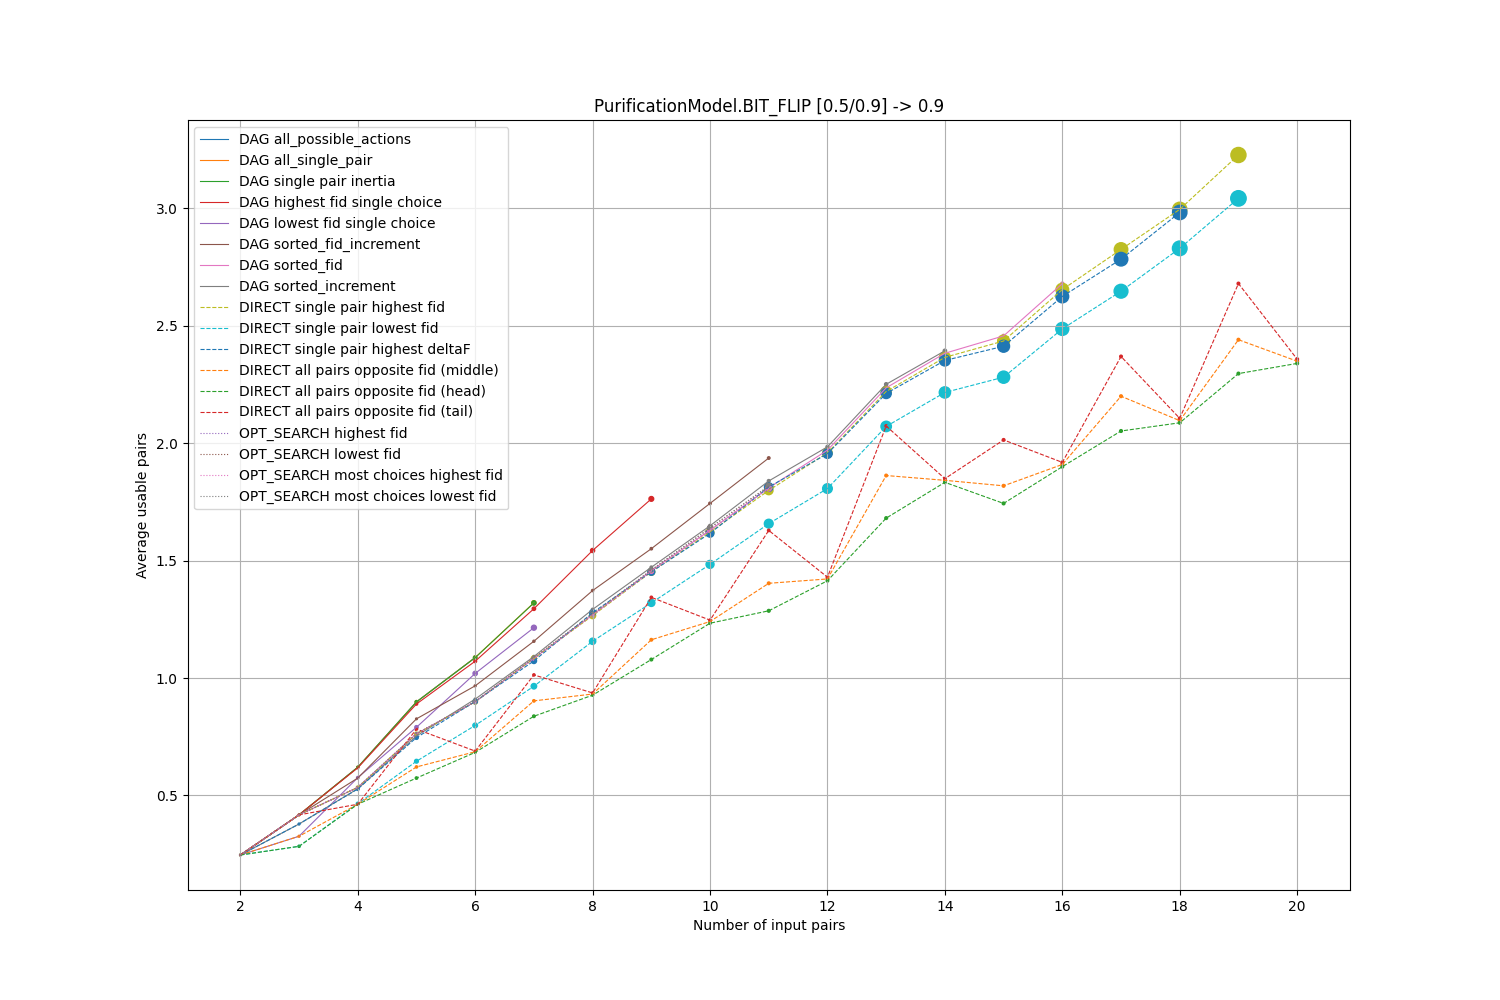

In [4]:
# pyright: strict
from __future__ import annotations
%matplotlib widget
import json
from collections import defaultdict

import matplotlib.pyplot as plt
from matplotlib.backend_bases import Event, PickEvent
from matplotlib.collections import PathCollection
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

IN_PATH = "sim_results.json"

Row = dict[str, str | int | float]


def plot_config(config_name: str, rows: list[Row]) -> None:
    # Rebuild strategy order (first-seen) and per-strategy type from the rows.
    strategy_order: list[str] = []
    strategy_types: dict[str, str] = {}
    # (strategy_name, num_pairs) -> list of (usable, steps)
    grouped: dict[tuple[str, int], list[tuple[float, float]]] = defaultdict(list)

    for row in rows:
        name = str(row["strategy_name"])
        if name not in strategy_types:
            strategy_order.append(name)
            strategy_types[name] = str(row["strategy_type"])
        num_pairs = int(row["num_pairs"])
        grouped[(name, num_pairs)].append((float(row["usable"]), float(row["steps"])))

    fig, ax = plt.subplots(figsize=(15, 10)) # pyright: ignore[reportUnknownMemberType]
    if fig.canvas.manager is not None:
        fig.canvas.manager.set_window_title(config_name) # pyright: ignore[reportUnknownMemberType]

    line_map: dict[str, tuple[Line2D, PathCollection]] = {}  # legend line -> (line, scatter)

    for strategy_name in strategy_order:
        strategy_type = strategy_types[strategy_name]

        average_usable_list: list[float] = []
        average_steps_list: list[float] = []
        num_pairs_list: list[int] = []

        # num_pairs values this strategy has any rows for, in ascending order
        this_strategy_num_pairs = sorted({np for (name, np) in grouped if name == strategy_name})
        for num_pairs in this_strategy_num_pairs:
            samples = grouped[(strategy_name, num_pairs)]
            if len(samples) == 0:
                continue
            samples_usable = [t[0] for t in samples]
            samples_steps = [t[1] for t in samples]
            avg_usable = sum(samples_usable) / len(samples_usable)
            avg_steps = sum(samples_steps) / len(samples_steps)
            num_pairs_list.append(num_pairs)
            average_usable_list.append(avg_usable)
            average_steps_list.append(avg_steps)

        line, = ax.plot( # pyright: ignore[reportUnknownMemberType]
            num_pairs_list,
            average_usable_list,
            label=strategy_name,
            linewidth=0.8,
            linestyle="solid" if strategy_type == "DAG" else "dashed" if strategy_type == "DIRECT" else "dotted",
        )
        scatter = ax.scatter( # pyright: ignore[reportUnknownMemberType]
            num_pairs_list,
            average_usable_list,
            s=[(size)**2 for size in average_steps_list],
            label="_nolegend_",
        )
        line_map[strategy_name] = (line, scatter)

    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xlabel("Number of input pairs") # pyright: ignore[reportUnknownMemberType]
    ax.set_ylabel("Average usable pairs") # pyright: ignore[reportUnknownMemberType]
    ax.set_title(config_name) # pyright: ignore[reportUnknownMemberType]
    ax.grid(True) # pyright: ignore[reportUnknownMemberType]
    legend = ax.legend() # pyright: ignore[reportUnknownMemberType]

    for legend_line in legend.get_lines():
        legend_line.set_picker(True) # pyright: ignore[reportUnknownMemberType]
        legend_line.set_pickradius(6)

    def on_pick(event: Event) -> None:
        pick_event: PickEvent = event # pyright: ignore[reportAssignmentType]
        label = pick_event.artist.get_label()
        if label not in line_map:
            return
        line, scatter = line_map[label] # pyright: ignore[reportArgumentType]
        visible = not line.get_visible()
        line.set_visible(visible)
        scatter.set_visible(visible)
        pick_event.artist.set_alpha(1.0 if visible else 0.2)
        fig.canvas.draw_idle() # pyright: ignore[reportUnknownMemberType]

    fig.canvas.mpl_connect('pick_event', on_pick)


plt.close("all")  # avoid piling up figures when re-running the cell

with open(IN_PATH, "r") as f:
    all_rows: list[Row] = json.load(f)

if not all_rows:
    print("No rows in data file; nothing to plot.")
else:
    # dicts keep insertion order, so configs appear in the order simulated
    rows_by_config: dict[str, list[Row]] = defaultdict(list)
    for row in all_rows:
        rows_by_config[str(row["config_name"])].append(row)

    for config_name, config_rows in rows_by_config.items():
        plot_config(config_name, config_rows)

    plt.show() # pyright: ignore[reportUnknownMemberType]